## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [1]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una tienda necesita administrar su inventario y consultar productos sin recorrer una lista completa. Para esto se implementa manualmente una tabla hash cuyo tamaño m lo indica el usuario y cuya llave es el código numérico del producto.

Cada producto almacena código, nombre, precio y cantidad disponible. La posición se calcula con h(código) = código % m. Si varios códigos producen el mismo índice, se utiliza encadenamiento: cada posición contiene una lista de productos.

El sistema permite insertar productos sin códigos repetidos, buscar, eliminar, actualizar cantidades y mostrar toda la tabla.


## 2) Requerimientos **[2 pts]**

### RQFs (Funcionales)
1. Solicitar el tamaño m de la tabla hash.
2. Registrar productos con código, nombre, precio y cantidad.
3. Calcular la posición con código % m.
4. Resolver colisiones mediante encadenamiento.
5. Impedir el registro de códigos duplicados.
6. Buscar productos por código y mostrar sus datos.
7. Eliminar un producto por su código.
8. Actualizar la cantidad disponible de un producto.
9. Mostrar todos los índices y sus productos, incluidos los índices vacíos.

### RQNFs (No funcionales)
1. Implementar la tabla hash manualmente, sin utilizar un diccionario como estructura principal.
2. Mantener el código organizado en funciones y una clase.
3. Validar que el tamaño de la tabla sea positivo.
4. Mostrar mensajes claros cuando un producto no exista o un código esté repetido.
5. Utilizar encadenamiento para manejar las colisiones.


## 3) Historias de usuario **[2 pts]**

### HU 1. Registrar productos
Como empleado, quiero registrar un producto con su código, nombre, precio y cantidad para mantener actualizado el inventario.

RQF-01. Solicitar tamaño de la tabla.
-Criterio de aceptación: ingresa un tamaño entero positivo.
- Criterio de error: ingresa un valor inválido.
- Salida: crea la tabla hash o finaliza el programa.

RQF-02. Registrar producto.
- Criterio de aceptación: ingresa los datos del producto correctamente.
- Criterio de error: datos inválidos o código repetido.
- Salida: registra el producto o informa el error.

RQF-03. Calcular posición.
- Criterio de aceptación: utiliza el código mediante la función hash.
- Criterio de error: no aplica.
- Salida: obtiene el índice correspondiente.

RQF-04. Resolver colisiones.
- Criterio de aceptación: varios productos pueden compartir índice.
- Criterio de error: no aplica.
- Salida: almacena los productos en la misma cadena.

RQF-05. Impedir códigos duplicados.
- Criterio de aceptación: el código no está registrado.
- Criterio de error: el código ya existe.
- Salida: permite insertar el producto o rechaza el registro.

### HU 2. Buscar y eliminar productos
Como empleado o administrador, quiero buscar y eliminar productos por su código para consultar sus datos o retirarlos del inventario.

RQF-06. Buscar productos por código y mostrar sus datos.
- Criterio de aceptación: el producto existe en la tabla.
- Criterio de error: el producto no está registrado.
- Salida: muestra los datos del producto o informa que no existe.

RQF-07. Eliminar producto por código.
- Criterio de aceptación: encuentra el producto en su cadena.
- Criterio de error: el producto no se encuentra.
- Salida: elimina únicamente el producto indicado o informa que no existe.

### HU 3. Actualizar y consultar inventario
Como empleado o administrador, quiero actualizar las cantidades y visualizar la tabla completa para mantener y revisar el inventario.

RQF-08. Actualizar cantidad disponible.
- Criterio de aceptación: el producto existe y la cantidad es válida.
- Criterio de error: producto inexistente o cantidad negativa.
- Salida: modifica la cantidad y confirma la actualización.

RQF-09. Mostrar índices y productos.
- Criterio de aceptación: selecciona la opción de mostrar tabla.
- Criterio de error: no aplica.
- lida: muestra todos los índices, productos e índices vacíos.

## 4) Diagramas de flujo **[5 pts]**




### 5) Análisis de complejidad **[15 pts]**

Sea m el tamaño de la tabla y n la cantidad de productos almacenados. La función hash realiza una operación módulo, por lo que su costo es O(1).

Con encadenamiento, insertar al inicio de la cadena cuesta O(1) si no se verifica duplicidad; en esta implementación se verifica primero que el código no exista, por lo que la inserción tiene el costo de la búsqueda en esa cadena. Buscar, eliminar y actualizar también dependen de la longitud de la cadena consultada.

- Mejor caso: la posición calculada está vacía o el producto está al inicio de la cadena. Costo O(1).
- Caso promedio: con una buena distribución de códigos, la longitud esperada de cada cadena es aproximadamente n/m. Buscar, eliminar, actualizar e insertar (por la verificación de duplicados) cuestan O(1 + n/m).
- Peor caso: todos los códigos caen en el mismo índice. La cadena tiene n elementos y buscar, eliminar, actualizar o insertar con verificación de duplicados cuesta O(n).
- Mostrar tabla: O(m + n), porque se revisan todos los índices y se muestran todos los productos.

Función T[n] para buscar: si k es la cantidad de elementos examinados en la cadena, T(n) = c₁ + c₂·k. En el mejor caso k = 1 (O(1)); en el peor caso k = n (O(n)).

La gráfica siguiente compara el crecimiento ilustrativo del mejor caso constante y el peor caso lineal.


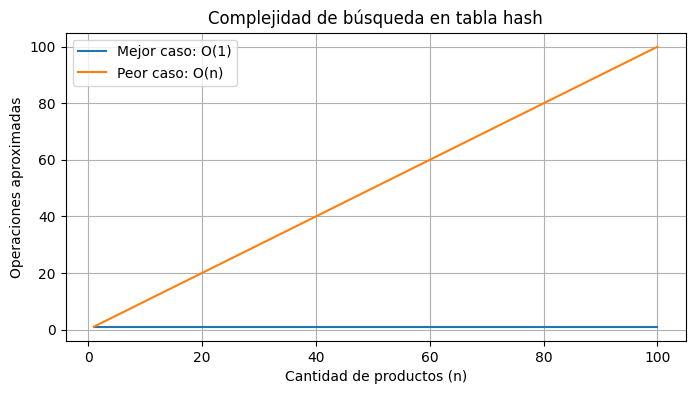

In [2]:
import matplotlib.pyplot as plt

n = list(range(1, 101))
mejor = [1 for _ in n]       # O(1)
peor = n                     # O(n)

plt.figure(figsize=(8, 4))
plt.plot(n, mejor, label="Mejor caso: O(1)")
plt.plot(n, peor, label="Peor caso: O(n)")
plt.xlabel("Cantidad de productos (n)")
plt.ylabel("Operaciones aproximadas")
plt.title("Complejidad de búsqueda en tabla hash")
plt.legend()
plt.grid(True)
plt.show()


## 6) Código funcional **[15 pts]**




In [2]:
class Producto:
    def __init__(self, codigo, nombre, precio, cantidad):
        self.codigo = int(codigo)
        self.nombre = str(nombre)
        self.precio = float(precio)
        self.cantidad = int(cantidad)

    def __str__(self):
        return (f"{self.codigo} - {self.nombre} - "
                f"${self.precio:,.0f} - {self.cantidad} unidades")


class TablaHash:
    def __init__(self, m):
        if not isinstance(m, int) or m <= 0:
            raise ValueError("El tamaño de la tabla debe ser un entero positivo.")
        self.m = m
        self.tabla = [[] for _ in range(m)]

    def funcion_hash(self, codigo):
        return int(codigo) % self.m

    def insertar(self, codigo, nombre, precio, cantidad):
        indice = self.funcion_hash(codigo)
        cadena = self.tabla[indice]

        for producto in cadena:
            if producto.codigo == int(codigo):
                print("No se insertó: el código ya está registrado.")
                return False

        nuevo = Producto(codigo, nombre, precio, cantidad)
        cadena.append(nuevo)
        print(f"Producto insertado en el índice {indice}.")
        return True

    def buscar(self, codigo):
        indice = self.funcion_hash(codigo)
        for producto in self.tabla[indice]:
            if producto.codigo == int(codigo):
                return producto
        return None

    def eliminar(self, codigo):
        indice = self.funcion_hash(codigo)
        cadena = self.tabla[indice]

        for posicion, producto in enumerate(cadena):
            if producto.codigo == int(codigo):
                eliminado = cadena.pop(posicion)
                print(f"Producto eliminado: {eliminado.nombre}.")
                return True

        print("No se encontró el producto.")
        return False

    def actualizar_cantidad(self, codigo, nueva_cantidad):
        if int(nueva_cantidad) < 0:
            print("La cantidad no puede ser negativa.")
            return False

        producto = self.buscar(codigo)
        if producto is None:
            print("No se encontró el producto.")
            return False

        producto.cantidad = int(nueva_cantidad)
        print(f"Inventario actualizado: {producto.nombre} - "
              f"{producto.cantidad} unidades.")
        return True

    def mostrar(self):
        print("\n" + "=" * 55)
        print("                 TABLA HASH")
        print("=" * 55)
        for indice, cadena in enumerate(self.tabla):
            if not cadena:
                print(f"{indice} -> Vacío")
            else:
                contenido = " | ".join(str(producto) for producto in cadena)
                print(f"{indice} -> {contenido}")
        print("=" * 55)


def menu():
    try:
        m = int(input("Ingrese el tamaño de la tabla hash: "))
        inventario = TablaHash(m)
    except ValueError as error:
        print("Dato inválido:", error)
        return

    while True:
        print("\n1. Insertar producto")
        print("2. Buscar producto")
        print("3. Eliminar producto")
        print("4. Actualizar cantidad")
        print("5. Mostrar tabla")
        print("6. Salir")
        opcion = input("Seleccione una opción: ")

        if opcion == "1":
            try:
                codigo = int(input("Código: "))
                nombre = input("Nombre: ")
                precio = float(input("Precio: "))
                cantidad = int(input("Cantidad: "))
                if precio < 0 or cantidad < 0:
                    print("Precio y cantidad deben ser valores no negativos.")
                else:
                    inventario.insertar(codigo, nombre, precio, cantidad)
            except ValueError:
                print("Ingrese valores numéricos válidos.")
        elif opcion == "2":
            try:
                codigo = int(input("Código que desea buscar: "))
                producto = inventario.buscar(codigo)
                if producto:
                    print("Producto encontrado:", producto)
                else:
                    print("El producto no está registrado.")
            except ValueError:
                print("El código debe ser numérico.")
        elif opcion == "3":
            try:
                codigo = int(input("Código que desea eliminar: "))
                inventario.eliminar(codigo)
            except ValueError:
                print("El código debe ser numérico.")
        elif opcion == "4":
            try:
                codigo = int(input("Código del producto: "))
                cantidad = int(input("Nueva cantidad: "))
                inventario.actualizar_cantidad(codigo, cantidad)
            except ValueError:
                print("Ingrese valores numéricos válidos.")
        elif opcion == "5":
            inventario.mostrar()
        elif opcion == "6":
            print("Fin del programa.")
            break
        else:
            print("Opción no válida.")


# Demostración de todos los requisitos solicitados
inventario = TablaHash(7)

print("CREACIÓN E INSERCIÓN")
inventario.insertar(101, "Arroz", 4500, 20)
inventario.insertar(108, "Huevos", 16000, 12)  # Colisión cuando ambos dan índice 3
inventario.insertar(115, "Azúcar", 5200, 18)   # También queda en índice 3
inventario.insertar(312, "Café", 12000, 10)
inventario.insertar(209, "Leche", 3800, 15)
inventario.mostrar()

print("\nBÚSQUEDA EXITOSA")
producto = inventario.buscar(108)
if producto:
    print("Producto encontrado:", producto)

print("\nBÚSQUEDA INEXISTENTE")
producto = inventario.buscar(999)
if producto:
    print("Producto encontrado:", producto)
else:
    print("El producto no está registrado.")

print("\nELIMINACIÓN")
inventario.eliminar(108)

print("\nACTUALIZACIÓN")
inventario.actualizar_cantidad(101, 35)

print("\nESTADO FINAL")
inventario.mostrar()



CREACIÓN E INSERCIÓN
Producto insertado en el índice 3.
Producto insertado en el índice 3.
Producto insertado en el índice 3.
Producto insertado en el índice 4.
Producto insertado en el índice 6.

                 TABLA HASH
0 -> Vacío
1 -> Vacío
2 -> Vacío
3 -> 101 - Arroz - $4,500 - 20 unidades | 108 - Huevos - $16,000 - 12 unidades | 115 - Azúcar - $5,200 - 18 unidades
4 -> 312 - Café - $12,000 - 10 unidades
5 -> Vacío
6 -> 209 - Leche - $3,800 - 15 unidades

BÚSQUEDA EXITOSA
Producto encontrado: 108 - Huevos - $16,000 - 12 unidades

BÚSQUEDA INEXISTENTE
El producto no está registrado.

ELIMINACIÓN
Producto eliminado: Huevos.

ACTUALIZACIÓN
Inventario actualizado: Arroz - 35 unidades.

ESTADO FINAL

                 TABLA HASH
0 -> Vacío
1 -> Vacío
2 -> Vacío
3 -> 101 - Arroz - $4,500 - 35 unidades | 115 - Azúcar - $5,200 - 18 unidades
4 -> 312 - Café - $12,000 - 10 unidades
5 -> Vacío
6 -> 209 - Leche - $3,800 - 15 unidades


## 7) Tests aplicados **[15 pts]**


In [3]:

prueba = TablaHash(7)

assert prueba.funcion_hash(101) == 3
assert prueba.insertar(101, "Arroz", 4500, 20) is True
assert prueba.insertar(108, "Huevos", 16000, 12) is True
assert prueba.insertar(115, "Azúcar", 5200, 18) is True

# Los tres productos deben estar en la misma cadena (colisión)
assert len(prueba.tabla[3]) == 3

assert prueba.insertar(101, "Otro arroz", 5000, 5) is False
assert prueba.buscar(101).nombre == "Arroz"

# Búsqueda de un producto inexistente
assert prueba.buscar(999) is None

# Actualización de inventario
assert prueba.actualizar_cantidad(101, 35) is True
assert prueba.buscar(101).cantidad == 35

# Eliminación de un elemento intermedio de la cadena
assert prueba.eliminar(108) is True
assert prueba.buscar(108) is None
assert len(prueba.tabla[3]) == 2

# El resto de productos de la cadena deben conservarse
assert prueba.buscar(101) is not None
assert prueba.buscar(115) is not None



Producto insertado en el índice 3.
Producto insertado en el índice 3.
Producto insertado en el índice 3.
No se insertó: el código ya está registrado.
Inventario actualizado: Arroz - 35 unidades.
Producto eliminado: Huevos.
